# Product Mix Optimization Using Linear Programming

## Task 4 – Optimization Model

This notebook solves an educational manufacturing product-mix problem with integer linear programming.

## Business Problem

A manufacturer produces Products A, B, and C. The objective is to maximize total profit while respecting labor, material, machine-hour, and market-demand limits. The data is synthetic and educational.

## Business Scenario

Each product earns a different contribution profit and consumes scarce production resources. Production quantities must be non-negative integers.

## Input Data and Assumptions

Profit per unit is A=$40, B=$55, C=$70. Labor requirements are 2, 3, 4 hours; material requirements are 3, 4, 5 units; and machine requirements are 1, 2, 3 hours for A, B, and C respectively. Demand limits are A=100, B=80, C=60. Capacities are labor=300, material=420, and machine=180.

## Decision Variables

A, B, and C represent the non-negative integer units produced of Products A, B, and C.

## Objective Function

Maximize: `40A + 55B + 70C`.

## Constraints

- Labor: `2A + 3B + 4C <= 300`
- Material: `3A + 4B + 5C <= 420`
- Machine: `A + 2B + 3C <= 180`
- Demand: `A <= 100`, `B <= 80`, `C <= 60`
- Non-negativity and integer restrictions apply to all variables.

## Mathematical Formulation

`max 40A + 55B + 70C` subject to the constraints above, with A, B, C in non-negative integers.

## Import Libraries

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
import pulp

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.optimization import DATA, build_problem, calculate_resource_usage, create_results_tables, save_results, print_business_insights

## Build PuLP Model

In [2]:
problem, quantities = build_problem(DATA)
problem

Product_Mix_Optimization:
MAXIMIZE
40*Production_A + 55*Production_B + 70*Production_C + 0.0
SUBJECT TO
Labor_Capacity: 2 Production_A + 3 Production_B + 4 Production_C <= 300

Material_Capacity: 3 Production_A + 4 Production_B + 5 Production_C <= 420

Machine_Capacity: Production_A + 2 Production_B + 3 Production_C <= 180

A_Demand: Production_A <= 100

B_Demand: Production_B <= 80

C_Demand: Production_C <= 60

VARIABLES
0 <= Production_A Integer
0 <= Production_B Integer
0 <= Production_C Integer

## Solve Optimization

In [3]:
problem.solve(pulp.PULP_CBC_CMD(msg=False))
status = pulp.LpStatus[problem.status]
if status != 'Optimal':
    raise RuntimeError(f'Solver status: {status}')
print('Solver Status:', status)

Solver Status: Optimal


## Optimal Production Plan

In [4]:
product_results, resource_results, total_production, total_profit = create_results_tables(quantities, DATA)
product_results

,Product,Optimal_Quantity,Profit_Per_Unit,Total_Profit
0,Product A,90,40,3600
1,Product B,0,55,0
2,Product C,30,70,2100


## Maximum Profit

In [5]:
print(f'Total production: {total_production} units')
print(f'Maximum profit: ${total_profit:,.0f}')
assert total_profit == pulp.value(problem.objective)

Total production: 120 units
Maximum profit: $5,700


## Resource Utilization

In [6]:
resource_results

,Resource,Used,Capacity,Remaining,Utilization_%
0,Labor,300.0,300,0.0,100.0
1,Material,420.0,420,0.0,100.0
2,Machine,180.0,180,0.0,100.0


## Product Profit Contribution

In [7]:
product_results[['Product', 'Total_Profit']]

,Product,Total_Profit
0,Product A,3600
1,Product B,0
2,Product C,2100


## Visualizations

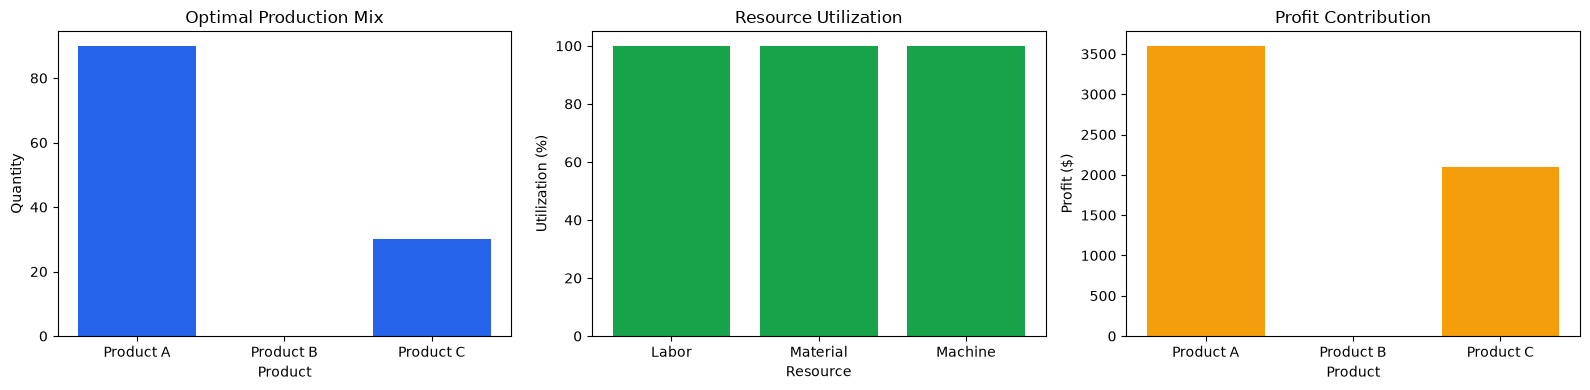

In [8]:
save_results(product_results, resource_results, Path(PROJECT_ROOT) / 'results')
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].bar(product_results['Product'], product_results['Optimal_Quantity'], color='#2563eb')
axes[0].set(title='Optimal Production Mix', xlabel='Product', ylabel='Quantity')
axes[1].bar(resource_results['Resource'], resource_results['Utilization_%'], color='#16a34a')
axes[1].set(title='Resource Utilization', xlabel='Resource', ylabel='Utilization (%)')
axes[2].bar(product_results['Product'], product_results['Total_Profit'], color='#f59e0b')
axes[2].set(title='Profit Contribution', xlabel='Product', ylabel='Profit ($)')
fig.tight_layout()
plt.show()

## Business Insights

In [9]:
print_business_insights(product_results, resource_results, DATA)

Largest production quantity: Product A (90 units)
Largest profit contribution: Product A ($3,600)
Main bottleneck resource(s): Labor, Material, Machine
Resources with unused capacity: None
Binding demand limit(s): None
Resource allocation insight: the optimal mix prioritizes products while respecting all capacity and demand limits.


## Limitations

The data is synthetic/educational. Demand values and resource availability are assumed. The model is deterministic and uncertainty is not explicitly modeled. A real business may need setup costs, shifts, inventory, lead times, quality, cash, and many other constraints.

## Conclusion

PuLP identifies the highest-profit feasible integer production mix and makes resource trade-offs transparent.